In [1]:
import numpy as np
from scipy.sparse.linalg import svds
import fastplotlib as fpl
from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
from itertools import product
from typing import *
from time import time
import tifffile
import h5py

No windowing system present. Using surfaceless platform
No config found!
No config found!


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Available devices:
✅ (default) | NVIDIA H100 PCIe | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 16.0.6, 256 bits) | CPU | Vulkan | Mesa 24.0.0-devel (git-3ca1f35cbf) (LLVM 16.0.6)
❗ | NVIDIA H100 PCIe/PCIe/SSE2 | Unknown | OpenGL | 


In [3]:
f = h5py.File("/mnt/home/kkolar/data/gcamp8f/jGCaMP8f_ANM471993_cell01.nwb")

In [4]:
f.keys()

<KeysViewHDF5 ['acquisition', 'analysis', 'file_create_date', 'general', 'identifier', 'intervals', 'processing', 'session_description', 'session_start_time', 'specifications', 'stimulus', 'timestamps_reference_time']>

In [5]:
movie = f["acquisition"]["Registered movie 1"]["data"][()]

In [16]:
std = np.std(movie, axis=0)

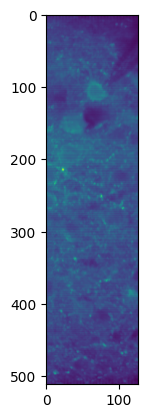

In [17]:
plt.imshow(std)

In [9]:
iw = fpl.ImageWidget(movie, cmap="gnuplot2")
iw.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [10]:
sel = iw.gridplot[0, 0].selectors[0]
vs = sel.get_vertices()
x1, x2 = int(vs[:, 0].min()), int(vs[:, 0].max())
y1, y2 = int(vs[:, 1].min()), int(vs[:, 1].max())

In [11]:
crop = movie[:, y1:y2, x1:x2]
iw_crop = fpl.ImageWidget(crop, cmap="gnuplot2")
iw_crop.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [12]:
crop = crop - crop.mean(axis=0)

In [35]:
%matplotlib ipympl

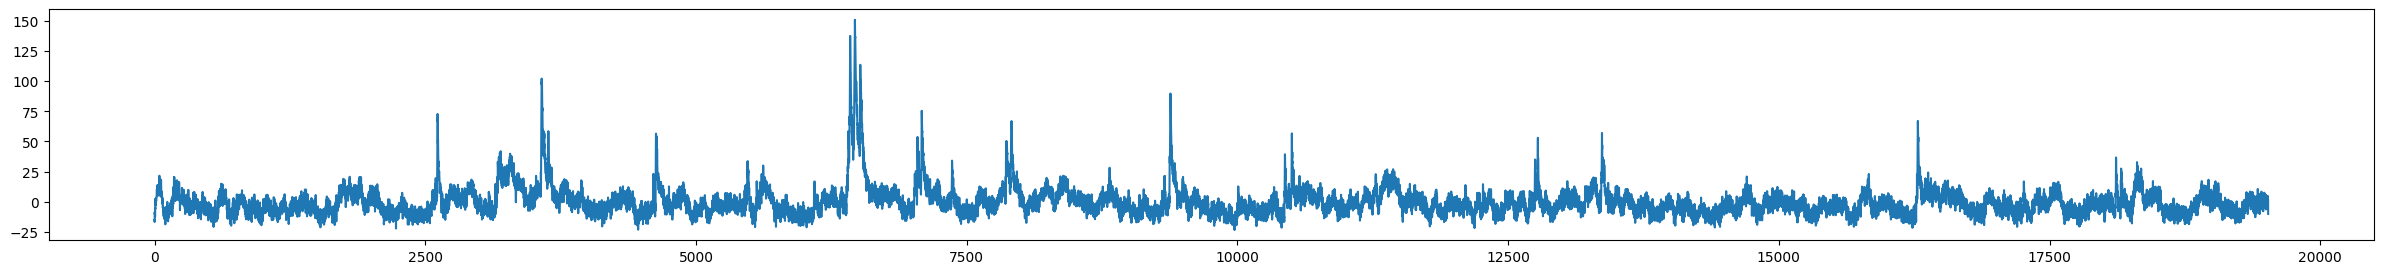

In [13]:
fig = plt.figure(figsize=(30, 3))
plt.plot(crop.mean(axis=(1, 2)))
plt.show()

In [78]:
plt.close()

In [14]:
class TdSVD:
    def __init__(
        self,
        movie: np.ndarray,
        n_time_steps: int,
        delay: int,
    ):
        self.n_time_steps = n_time_steps
        self.movie_mean = movie.mean(axis=0)
        
        frame = movie[0]
        self.xdim, self.ydim = frame.shape[0], frame.shape[1]
        
        n_pixels = self.xdim * self.ydim
        n_timepoints = movie.shape[0]
        
        self.A = np.zeros(shape=(n_pixels * n_time_steps, n_timepoints - n_time_steps), dtype=np.float32)
        A_ixs = np.zeros(n_pixels * n_time_steps)
        
        for pixel_ix, (x, y) in tqdm(enumerate(product(range(self.xdim), range(self.ydim))), total=n_pixels):
            for step in range(n_time_steps):
                self.A[(n_time_steps * pixel_ix) + step] = np.roll(movie[:, x, y], shift=-delay * step)[:-n_time_steps]

        self.k, self.U, self.S, self.V = None, None, None, None
    
    def fit(self, k=6, **kwargs):
        self.k = k
        t0 = time()
        self.U, self.S, self.V = svds(self.A, k=k, **kwargs)
        self.U = self.U[:, ::-1]
        self.S = self.S[::-1]
        self.V = self.V[::-1, :]
        t1 = time()
        print(f"svd took: {t1 - t0:.02f} sec")

    def get_spatial(self):
        """
        Returns
        -------
        np.ndarray
            [n_time_steps, k, ydim, xdim]
        """
        return np.array([self.U.reshape((self.xdim, self.ydim, self.n_time_steps, self.k))[..., i, :].transpose(2, 0, 1) for i in range(self.n_time_steps)])

In [15]:
td_svd = TdSVD(
    movie=crop,
    n_time_steps=15,
    delay=1,
)

100%|███████████████████████████████████████████████████████████████████████████████████████████| 2448/2448 [00:01<00:00, 1698.32it/s]


In [16]:
td_svd.fit(k=10)

svd took: 5.07 sec


In [17]:
spatial = td_svd.get_spatial()

In [18]:
spatial.shape

(15, 10, 48, 51)

In [19]:
iw_steps = fpl.ImageWidget(
    data=[spatial[step] for step in range(td_svd.n_time_steps)],
    names=[f"step-{i}" for i in range(td_svd.n_time_steps)],
    grid_plot_kwargs={"size": (1500, 400)}
)
iw_steps.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…

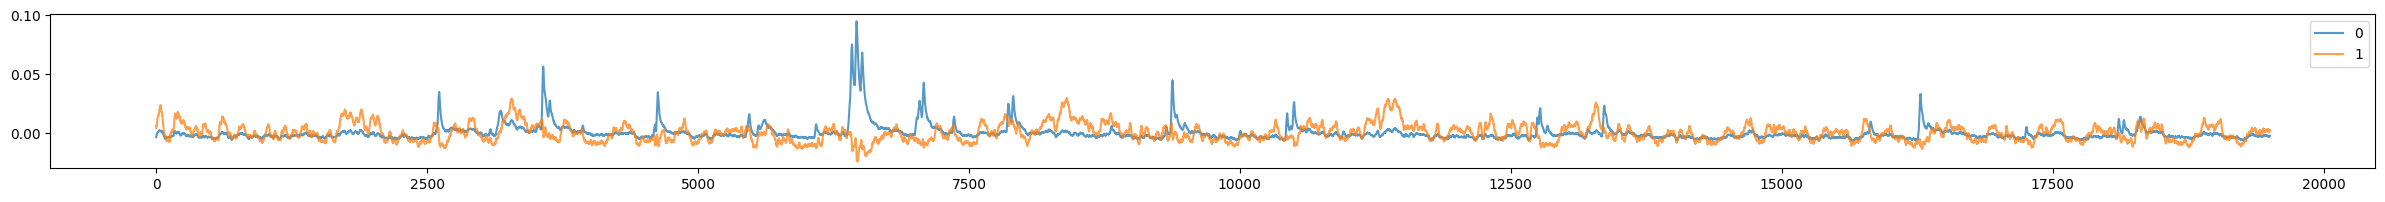

In [20]:
fig = plt.figure(figsize=(30, 2))

for i, vi in enumerate(td_svd.V):
    # fig = plt.figure(figsize=(50, 2))
    plt.plot(vi, label=str(i), alpha=0.75)
    # plt.show()
    if i == 1:
        break
    # plt.show()
plt.legend()
plt.show()

In [63]:
plt.close()

In [28]:
iw_steps = fpl.ImageWidget(
    data=[spatial[:, k_step] for k_step in range(td_svd.k)],
    names=[f"U-{i}" for i in range(td_svd.k)],
    grid_plot_kwargs={"size": (1500, 400)}
)

plot_lines = fpl.Plot()
plot_lines.docks["right"].size = 70

# legend = fpl.Legend(plot_lines.docks["right"])
# for i, (vi, c) in enumerate(zip(td_svd.V, ["red", "orange", "yellow", "green", "blue", "purple"])):
#     l = plot_lines.add_line(vi, colors=c, name=f"{i}")
    # legend.add_graphic(l, label=f"{i}---")

# plot_lines.show()

iw_steps.show()
# HBox([iw_steps.widget, plot_lines.widget])

RFBOutputContext()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…

In [22]:
u, s, v = svds(crop.reshape(crop.shape[0], crop.shape[1] * crop.shape[2]).T.astype(np.float32), k=10)

In [23]:
u = u[:, ::-1]
s = s[::-1]
v = v[::-1]

In [24]:
%matplotlib inline

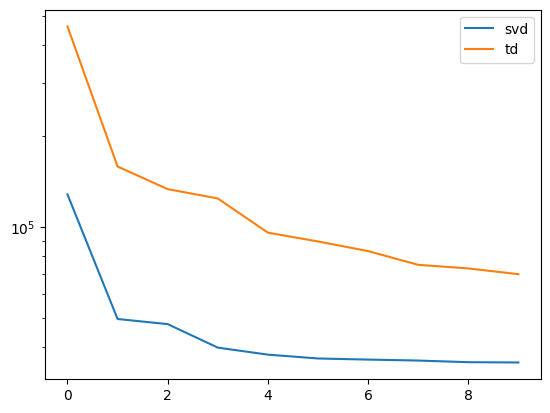

In [25]:
plt.plot(s[:], label="svd")
plt.plot(td_svd.S[:], label="td")
plt.yscale("log")
plt.legend()
plt.show()

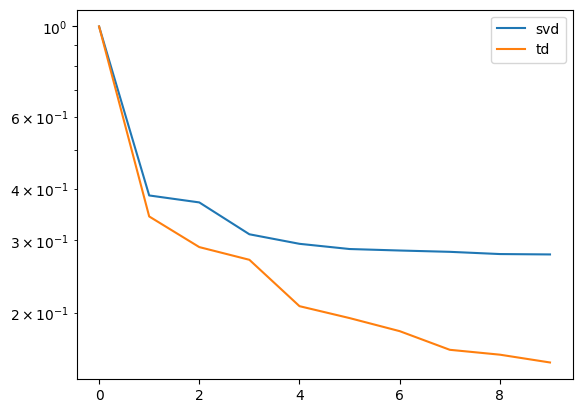

In [26]:
plt.plot(s[:] / s.max(), label="svd")
plt.plot(td_svd.S / td_svd.S.max(), label="td")
plt.yscale("log")
plt.legend()

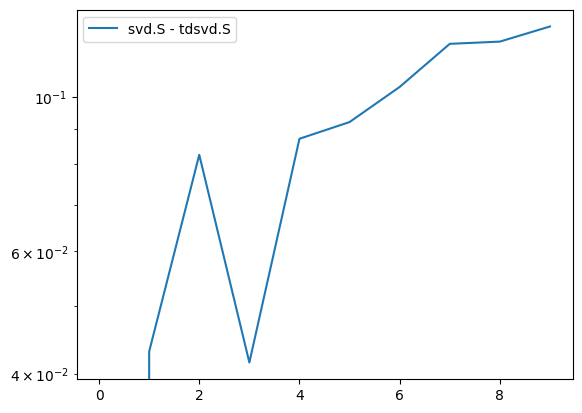

In [27]:
plt.plot((s[:] / s.max()) - (td_svd.S / td_svd.S.max()), label="svd.S - tdsvd.S")
plt.yscale("log")
plt.legend()